# Fully online inference: LR8_32 + CAPNetLite (2022train20)

Load the saved LR8_32 and CAPNetLite models and infer directly from raw `.tim` IQ:

`.tim -> BOI detection/filtering/frequency shift -> P96-clipped z -> FFT(z²), FFT(z⁴), FFT(|z|²) -> LR8_32 -> (LR-routed QPSK-like only) blind corrected Rs/CFO -> raw 11×15 CC from unclipped x_processed -> abs/order warping/BOI-power scaling -> CAPNetLite`.

The LR features, blind estimators, complex64/float32 CC implementation, and GELU CNN architecture match the current generation/training notebooks. P96 clipping is used for FFT features and blind estimates; the CC uses the **unclipped** BOI waveform.

Evaluation uses **2022 held-out test indices from `group_split_70_5_25alter/splits`** and **all eligible 2018 indices**. Negative-SNR 2018 samples are excluded by the existing manifest. No training, split regeneration, or precomputed BOI/FFT/CC input files are used.

Truth labels and SNR are used only to select evaluation rows and score predictions. Every LR QPSK-like decision runs the CNN, including false routes; there is no truth-based forced-QPSK fallback. Thus end-to-end accuracy may differ from the cached simulation.

Run from this notebook's directory with a fresh kernel. All paths are relative; weights have no random-seed suffix. Results are checkpointed to `fully_online_inference_results/LR8_32-CAPNetLite-2022train20.csv`. Resume is enabled for an interrupted run with the same models, configuration, and manifests; set `RESUME_FROM_EXISTING_CSV = False` for a fresh evaluation after changing them.

This notebook was generated without executing any cell.


In [ ]:
from pathlib import Path
import os
import sys

# Run with the Jupyter working directory set to this notebook's folder.
# Match the training notebooks' physical GPU assignments.
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
BASE_DIR = Path(".")
DATASET_ROOT = BASE_DIR / "../../CSPB.ML_dataset"
MODEL_DIR = BASE_DIR / "fully_online_pipeline_models"
ALTER_DIR = BASE_DIR / "group_split_70_5_25alter"
RESULT_DIR = BASE_DIR / "fully_online_inference_results"
SPLIT_MODE = "2022train20"
TRAIN_YEAR = 2022
EXT_YEAR = 2018
RESULT_CSV = RESULT_DIR / f"LR8_32-CAPNetLite-{SPLIT_MODE}.csv"
RESUME_FROM_EXISTING_CSV = True
CHECKPOINT_EVERY = 100

for import_dir in (BASE_DIR, ALTER_DIR):
    if str(import_dir) not in sys.path:
        sys.path.insert(0, str(import_dir))

import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix
from types import SimpleNamespace

from helper_function import pre_boi_p96_fft2_generator as fe
from helper_function.pre_qpsklike_cc_11x15_float32_generator import build_qpsklike_cc_11x15_float32
from split_utils import split_index_sets, run_manifest_inference

# Guard against a helper_function module cached from a different project.
if not (BASE_DIR / "helper_function").samefile(Path(fe.__file__).parent):
    raise RuntimeError("A different project's helper_function is already imported; restart the kernel here.")

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ["QPSK", "16QAM", "64QAM", "256QAM"]
LR_LABEL5_ORDER = ["BPSK", "MSK", "DQPSK", "8PSK", "QPSK-like"]
FULL8_LABEL_ORDER = ["BPSK", "MSK", "DQPSK", "8PSK", "QPSK", "16QAM", "64QAM", "256QAM"]
CC_COLUMN_ORDERS = torch.tensor([2] * 3 + [4] * 5 + [6] * 7, dtype=torch.float32)
CC_SCALE_EPS = torch.tensor(1e-12, dtype=torch.float32)

# Identical BOI/FFT settings to pre_BOI+FFT-Generate-*-compact-vectors-final.ipynb.
CFG = {
    'N_PER_BATCH': 4000,
    'N_BATCHES': 28,
    'N_TOTAL': 112000,
    'SAMPLES_PER_SIG': 32768,
    'FS_IN': 1.0,
    'EPS': 1e-12,
    'DELTA_F0': 0.002,
    'THRESHOLD_DB': 5.0,
    'BOUNDARY_THRESHOLD_DB': 1.5,
    'BOI_SELECT_MODE': 'strongest',
    'MERGE_GAP_W_FACTOR': 2.0,
    'MAX_EXPAND_W_FACTOR': 8.0,
    'BOI_GUARD_BINS': 2,
    'ADAPTIVE_FILTER_EXPAND': True,
    'FILTER_EXPAND_RATIO': 0.2,
    'FILTER_EXPAND_RATIO_LOW_SNR': 0.3,
    'FILTER_EXPAND_RATIO_MID_SNR': 0.15,
    'FILTER_EXPAND_RATIO_HIGH_SNR': 0.05,
    'SNR_LOW_TH_DB': 4.0,
    'SNR_HIGH_TH_DB': 8.0,
    'MAX_EXPANDED_FILTER_BW_FRAC': 0.95,
    'FFT_NFFT': 32768,
    'FFT_WINDOW': 'hann',
    'FFT_TOP_K': 20,
    'FFT_PEAK_MIN_SEP_BINS': 8,
    'GUIDE_KMAX_INTEGER_RS': 5,
    'GUIDE_KMAX_HALF_RS': 5,
    'GUIDE_SEARCH_BINS': 3,
}

print("Working directory:", BASE_DIR)
print("Dataset root:", DATASET_ROOT)
print("Split:", SPLIT_MODE)
print("Device:", DEVICE)
print("Output CSV:", RESULT_CSV)


## Load the existing group split

Use the same held-out and external index sets as the training notebook. The stored manifests are read only.


In [2]:
# Read the existing manifests only: do not regenerate or overwrite any split.
manifests = {}
for year in (2018, 2022):
    path = ALTER_DIR / "splits" / f"{year}_group_split.csv"
    frame = pd.read_csv(path, dtype={"InbandSNRdB": str})
    required = {"SignalIndex", "SignalType", "InbandSNRdB", "group_id", "split"}
    if not required.issubset(frame.columns) or frame.empty:
        raise ValueError(f"Invalid split manifest: {path}")
    indices = pd.to_numeric(frame["SignalIndex"], errors="raise")
    if not (indices.eq(indices.astype(int)) & indices.between(1, CFG["N_TOTAL"])).all():
        raise ValueError(f"Invalid signal indices in {path}")
    frame["SignalIndex"] = indices.astype(int)
    if frame["SignalIndex"].duplicated().any():
        raise ValueError(f"Duplicate signal indices in {path}")
    if not frame["split"].isin(["train", "val", "test"]).all():
        raise ValueError(f"Invalid split names in {path}")
    if frame.groupby("group_id")["split"].nunique().max() != 1:
        raise ValueError(f"Parameter-group leakage in {path}")
    snr = pd.to_numeric(frame["InbandSNRdB"], errors="raise")
    if not np.isfinite(snr).all() or (year == 2018 and (snr < 0).any()):
        raise ValueError(f"Invalid SNR selection in {path}")
    if not frame["SignalType"].str.upper().isin(FULL8_LABEL_ORDER).all():
        raise ValueError(f"Unsupported signal labels in {path}")
    manifests[year] = frame

split_indices = split_index_sets(manifests, TRAIN_YEAR)
evaluation_targets = {
    TRAIN_YEAR: manifests[TRAIN_YEAR].loc[manifests[TRAIN_YEAR]["split"].eq("test")].copy(),
    EXT_YEAR: manifests[EXT_YEAR].copy(),
}
if not all(len(frame) for frame in evaluation_targets.values()):
    raise ValueError("Both evaluation sets must contain samples")
assert set(evaluation_targets[TRAIN_YEAR]["SignalIndex"]) == split_indices["test"]
assert set(evaluation_targets[EXT_YEAR]["SignalIndex"]) == split_indices["ext"]
display(pd.DataFrame([
    {"dataset": year, "evaluation": "same-domain test" if year == TRAIN_YEAR else "external test",
     "samples": len(frame)}
    for year, frame in evaluation_targets.items()
]))


,dataset,evaluation,samples
0,2022,same-domain test,28000
1,2018,external test,111632


## Load LR8_32 and CAPNetLite

The CNN and CC postprocessing definitions are copied from the current training notebook; weight loading is strict.


In [3]:
class ResBlock(nn.Module):
    def __init__(self, ch, kernel=3):
        super().__init__()
        pad = kernel // 2
        self.conv1 = nn.Conv2d(ch, ch, kernel_size=kernel, stride=1, padding=pad, bias=False)
        self.bn1 = nn.BatchNorm2d(ch)
        self.conv2 = nn.Conv2d(ch, ch, kernel_size=kernel, stride=1, padding=pad, bias=False)
        self.bn2 = nn.BatchNorm2d(ch)

    def forward(self, x):
        identity = x
        out = F.gelu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + identity
        return F.gelu(out)


class Stage(nn.Module):
    def __init__(self, ch, n_blocks, kernel):
        super().__init__()
        self.blocks = nn.ModuleList([ResBlock(ch, kernel) for _ in range(n_blocks)])

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        return x


class CAPNetLite(nn.Module):
    def __init__(self, n_classes=4, c1=20, c2=20, kernel=5, n_blocks1=3, n_blocks2=2):
        super().__init__()
        pad = kernel // 2
        self.stem = nn.Conv2d(1, c1, kernel_size=kernel, stride=1, padding=pad, bias=False)
        self.stem_bn = nn.BatchNorm2d(c1)
        self.block1 = Stage(c1, n_blocks1, kernel)
        self.down = nn.Conv2d(c1, c2, kernel_size=kernel, stride=(1, 2), padding=pad, bias=False)
        self.down_bn = nn.BatchNorm2d(c2)
        self.block2 = Stage(c2, n_blocks2, kernel)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(c2, n_classes)

    def forward(self, x):
        x = F.gelu(self.stem_bn(self.stem(x)))
        x = self.block1(x)
        x = F.gelu(self.down_bn(self.down(x)))
        x = self.block2(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)


def raw_cc_abs_warp_scale(raw_cc, power):
    """float32: abs -> |C(n,m)|**(2/n) -> divide by p_boi_inband_signal."""
    raw_cc = torch.as_tensor(raw_cc)
    if raw_cc.ndim != 4 or tuple(raw_cc.shape[1:]) != (1, 11, 15):
        raise ValueError(f"Expected raw cc_matrix [N,1,11,15], got {tuple(raw_cc.shape)}")
    if not torch.is_complex(raw_cc):
        raise TypeError(f"Expected complex raw CC, got {raw_cc.dtype}")
    power = torch.as_tensor(power, dtype=torch.float32).reshape(-1)
    if power.shape[0] != raw_cc.shape[0]:
        raise ValueError(f"Power count {power.shape[0]} != CC count {raw_cc.shape[0]}")

    magnitude = torch.abs(raw_cc.to(torch.complex64)).to(torch.float32)
    exponent = (torch.tensor(2.0, dtype=torch.float32) / CC_COLUMN_ORDERS).view(1, 1, 1, 15)
    warped = torch.pow(magnitude, exponent)  # exact zero remains zero
    return warped / (power.view(-1, 1, 1, 1) + CC_SCALE_EPS)

LR_MODEL_PATH = MODEL_DIR / f"lr8_32_{SPLIT_MODE}.joblib"
CAP_MODEL_PATH = MODEL_DIR / (
    f"capnet_lite_lr8_32_xprocrawcc_warpscale_k5_c20_20_nb3_2_{SPLIT_MODE}.pt"
)
for path in (LR_MODEL_PATH, CAP_MODEL_PATH):
    if not path.is_file():
        raise FileNotFoundError(path)

lr_artifact = joblib.load(LR_MODEL_PATH)
for key, expected in {
    "split_mode": SPLIT_MODE,
    "vector_key": "lr8_32",
    "source_schema": "boi_p96_fft2_full_v4",
}.items():
    if lr_artifact.get(key) != expected:
        raise ValueError(f"LR artifact {key}={lr_artifact.get(key)!r}; expected {expected!r}")
if list(lr_artifact["feature_names"]) != list(fe.LR8_32_FEATURES):
    raise ValueError("LR8_32 feature order does not match the current feature generator")
if list(lr_artifact["class_names"]) != LR_LABEL5_ORDER:
    raise ValueError("Unexpected LR class labels")
lr_model = lr_artifact["model"]
if int(lr_model.n_features_in_) != 32:
    raise ValueError("The LR model must accept exactly 32 features")

cap_model = CAPNetLite(n_classes=4, c1=20, c2=20, kernel=5, n_blocks1=3, n_blocks2=2)
cap_model.load_state_dict(torch.load(CAP_MODEL_PATH, map_location="cpu", weights_only=True), strict=True)
cap_model = cap_model.to(DEVICE).eval()
print("Loaded LR:", LR_MODEL_PATH)
print("Loaded CAPNetLite:", CAP_MODEL_PATH)
print("CAPNetLite parameters:", sum(p.numel() for p in cap_model.parameters()))


Loaded LR: fully_online_pipeline_models/lr8_32_2022train20.joblib
Loaded CAPNetLite: fully_online_pipeline_models/capnet_lite_lr8_32_xprocrawcc_warpscale_k5_c20_20_nb3_2_2022train20.pt
CAPNetLite parameters: 111064


## Define IQ-to-prediction inference

BOI and FFT functions come from the current local generator. The prediction methods do not receive truth metadata. Numerical or file errors stop inference with the sample index; successfully written CSV rows can be resumed.


In [4]:
def online_boi_fft(x, cfg):
    """IQ-only preprocessing; match the current generator's precision and FFT order."""
    boi_pack = fe.base.run_fixed_boi_detector(x, cfg)
    prepared = boi_pack["prepared"]
    boi_for_filter = prepared["selected_filter"]
    expanded_bw_frac = float(boi_for_filter["bandwidth"] / cfg["FS_IN"])
    if expanded_bw_frac >= float(cfg["MAX_EXPANDED_FILTER_BW_FRAC"]):
        boi_for_filter = prepared["selected_refined"]
    step_b = fe.base.extract_filter_shift_noresample(
        x=x, boi=boi_for_filter, fs=cfg["FS_IN"], guard_bins=cfg["BOI_GUARD_BINS"],
    )
    x_processed_full = np.asarray(step_b["x_processed"], dtype=np.complex128)
    # P96 clipping precedes complex64 rounding, exactly as in build_one_sample.
    z, _ = fe.prep_clip_p96(x_processed_full)
    x_processed = np.asarray(x_processed_full, dtype=np.complex64)
    z2 = np.asarray(z * z, dtype=np.complex64)
    z4 = np.asarray(z2 * z2, dtype=np.complex64)
    fft_z2_mag_db = fe.fft_mag_db_float32(z2, nfft=int(cfg["FFT_NFFT"]))
    fft_z4_mag_db = fe.fft_mag_db_float32(z4, nfft=int(cfg["FFT_NFFT"]))
    env2 = np.asarray(np.abs(z) ** 2, dtype=np.complex64)
    mag_db_env2 = fe.fft_mag_db_float32(env2, nfft=int(cfg["FFT_NFFT"]))
    vector = fe.lr8_32_features(fft_z2_mag_db, fft_z4_mag_db, mag_db_env2)
    power = np.float32(prepared["power_report"]["p_signal_boi_local"])
    return vector, x_processed, fft_z4_mag_db, mag_db_env2, power


class FullyOnlineLR8_32Pipeline:
    def __init__(self, dataset_root, cfg, lr_model, cap_model, device):
        self.dataset_root = Path(dataset_root)
        self.cfg = dict(cfg)
        self.lr_model = lr_model
        self.cap_model = cap_model
        self.device = torch.device(device)

    @torch.inference_mode()
    def predict_iq(self, x):
        """Return a prediction from IQ alone; no truth label, Rs, CFO, or SNR input."""
        x = np.asarray(x, dtype=np.complex128)
        if x.shape != (int(self.cfg["SAMPLES_PER_SIG"]),) or not np.isfinite(x).all():
            raise ValueError("Expected one finite raw IQ waveform of SAMPLES_PER_SIG samples")
        vector, x_processed, fft_z4, fft_env2, power = online_boi_fft(x, self.cfg)
        vector = np.asarray(vector, dtype=np.float32)
        if vector.shape != (32,):
            raise ValueError(f"Unexpected LR feature shape: {vector.shape}")
        # Match the training pipeline's nonfinite-feature handling (saved imputer).
        features = np.where(np.isfinite(vector), vector, np.nan).astype(np.float32)[None, :]
        coarse_pred = str(self.lr_model.predict(features)[0])
        if coarse_pred not in LR_LABEL5_ORDER:
            raise ValueError(f"Unexpected LR prediction: {coarse_pred}")
        if coarse_pred != "QPSK-like":
            return SimpleNamespace(coarse_pred=coarse_pred, pred_label=coarse_pred)

        # Every LR-routed sample reaches CC/CNN, irrespective of its true class.
        # Use the same fields and float32 rounding as the CC generation notebooks.
        rs_prom, _ = fe.blind_prominence_rs(fft_z4)
        rs = np.float32(fe.rs_prominence_fftz2_correction(fft_env2, rs_prom))
        cfo = np.float32(fe.cfo_band_interp(fft_z4))
        if not np.isfinite(rs) or rs <= 0 or not np.isfinite(cfo):
            raise ValueError(f"Invalid blind Rs/CFO estimates: {rs}, {cfo}")
        if not np.isfinite(power) or power <= 0:
            raise ValueError(f"Invalid BOI in-band signal power: {power}")
        x_tensor = torch.from_numpy(x_processed[None, :]).to(self.device, dtype=torch.complex64)
        raw_cc = build_qpsklike_cc_11x15_float32(
            x_tensor,
            torch.tensor([rs], device=self.device, dtype=torch.float32),
            torch.tensor([cfo], device=self.device, dtype=torch.float32),
        )
        # Training postprocess runs on CPU after the raw complex CC is saved.
        # Preserve that order: abs -> |C(n,m)|**(2/n) -> divide by (power + 1e-12).
        cap_input = raw_cc_abs_warp_scale(raw_cc.detach().cpu().unsqueeze(1), [power])
        if not bool(torch.isfinite(cap_input).all()):
            raise ValueError("Nonfinite CC input to CAPNetLite")
        logits = self.cap_model(cap_input.to(self.device))
        if not bool(torch.isfinite(logits).all()):
            raise ValueError("Nonfinite CAPNetLite logits")
        pred_label = CLASS_NAMES[int(logits.argmax(dim=1).item())]
        return SimpleNamespace(coarse_pred=coarse_pred, pred_label=pred_label)

    def process_signal(self, year, signal_index):
        """Use year/index only to locate a .tim file; no truth metadata is read."""
        year, signal_index = int(year), int(signal_index)
        if year not in (2018, 2022):
            raise ValueError(f"Unsupported dataset year: {year}")
        root_data = self.dataset_root / f"CSPB_ML_{year}_Data"
        tim_path, _ = fe.base.global_to_path(
            root_data, signal_index, self.cfg["N_PER_BATCH"], self.cfg["N_TOTAL"],
        )
        try:
            x = fe.base.tim_to_complex_iq(tim_path, self.cfg["SAMPLES_PER_SIG"])
            return self.predict_iq(x)
        except Exception as exc:
            # Stop on an error instead of silently excluding a sample from accuracy.
            raise RuntimeError(f"Inference failed for {year}/{signal_index}: {tim_path}") from exc


pipeline = FullyOnlineLR8_32Pipeline(DATASET_ROOT, CFG, lr_model, cap_model, DEVICE)


## Run inference and checkpoint the CSV

Running the next cell starts the full evaluation. The CSV retains the reference notebook schema: `dataset,index,snr_db,true_label,lr_prediction,nn_prediction`. Non-routed samples have an empty `nn_prediction`.


In [5]:
compact_results = run_manifest_inference(
    pipeline=pipeline,
    manifests=manifests,
    train_year=TRAIN_YEAR,
    output_csv=RESULT_CSV,
    resume=RESUME_FROM_EXISTING_CSV,
    checkpoint_every=CHECKPOINT_EVERY,
)
print("Saved:", RESULT_CSV)
print("CSV columns:", compact_results.columns.tolist())
print("CSV rows:", len(compact_results))
display(compact_results.groupby("dataset", sort=True).size().rename("rows").to_frame())


2022: 2022:   0%|          | 0/27699 [00:00<?, ?it/s]

2022: 2018:   0%|          | 0/111632 [00:00<?, ?it/s]

Saved: fully_online_inference_results/LR8_32-CAPNetLite-2022train20.csv
CSV columns: ['dataset', 'index', 'snr_db', 'true_label', 'lr_prediction', 'nn_prediction']
CSV rows: 139632


,rows
dataset,
2018,111632
2022,28000


## Accuracy from end-to-end predictions

Require complete coverage of both evaluation sets before reporting accuracy.


In [6]:
accuracy_results = pd.read_csv(RESULT_CSV, keep_default_na=False)
expected_keys = {
    (int(year), int(index))
    for year, frame in evaluation_targets.items() for index in frame["SignalIndex"]
}
actual_keys = set(zip(accuracy_results["dataset"].astype(int), accuracy_results["index"].astype(int)))
if len(actual_keys) != len(accuracy_results) or actual_keys != expected_keys:
    raise ValueError("The inference CSV is incomplete, duplicated, or does not match the evaluation split")
if not accuracy_results["lr_prediction"].isin(LR_LABEL5_ORDER).all():
    raise ValueError("Missing or invalid LR predictions in the inference CSV")
routed = accuracy_results["lr_prediction"].eq("QPSK-like")
if not accuracy_results.loc[routed, "nn_prediction"].isin(CLASS_NAMES).all():
    raise ValueError("Missing or invalid CNN predictions for LR-routed samples")
if accuracy_results.loc[~routed, "nn_prediction"].ne("").any():
    raise ValueError("Unexpected CNN predictions for non-routed samples")

# Validate evaluation metadata too when resuming an existing CSV.
for year, target in evaluation_targets.items():
    rows = accuracy_results.loc[accuracy_results["dataset"].eq(year)].set_index("index")
    reference = target.set_index("SignalIndex").loc[rows.index]
    if not np.array_equal(rows["true_label"].to_numpy(), reference["SignalType"].str.upper().to_numpy()):
        raise ValueError(f"Truth label mismatch in the {year} result CSV")
    if not np.allclose(rows["snr_db"].to_numpy(dtype=float), reference["InbandSNRdB"].to_numpy(dtype=float), rtol=1e-10, atol=1e-10):
        raise ValueError(f"SNR metadata mismatch in the {year} result CSV")

accuracy_results["final_prediction"] = np.where(
    routed, accuracy_results["nn_prediction"], accuracy_results["lr_prediction"],
)
evaluated = accuracy_results.copy()
evaluated["correct"] = evaluated["final_prediction"].eq(evaluated["true_label"])
accuracy_summary = evaluated.groupby("dataset", sort=True).agg(
    evaluated_samples=("correct", "size"),
    correct_predictions=("correct", "sum"),
    accuracy=("correct", "mean"),
)
accuracy_summary["accuracy_percent"] = accuracy_summary["accuracy"] * 100.0
accuracy_summary["evaluation"] = [
    "same-domain test" if int(year) == TRAIN_YEAR else "external test"
    for year in accuracy_summary.index
]
display(accuracy_summary.round(4))


,evaluated_samples,correct_predictions,accuracy,accuracy_percent,evaluation
dataset,,,,,
2018,111632,101663,0.9107,91.0698,external test
2022,28000,26465,0.9452,94.5179,same-domain test


## Combined 2018/2022 confusion matrix

One figure, retaining the current training notebook’s class order and red/green percentage style.


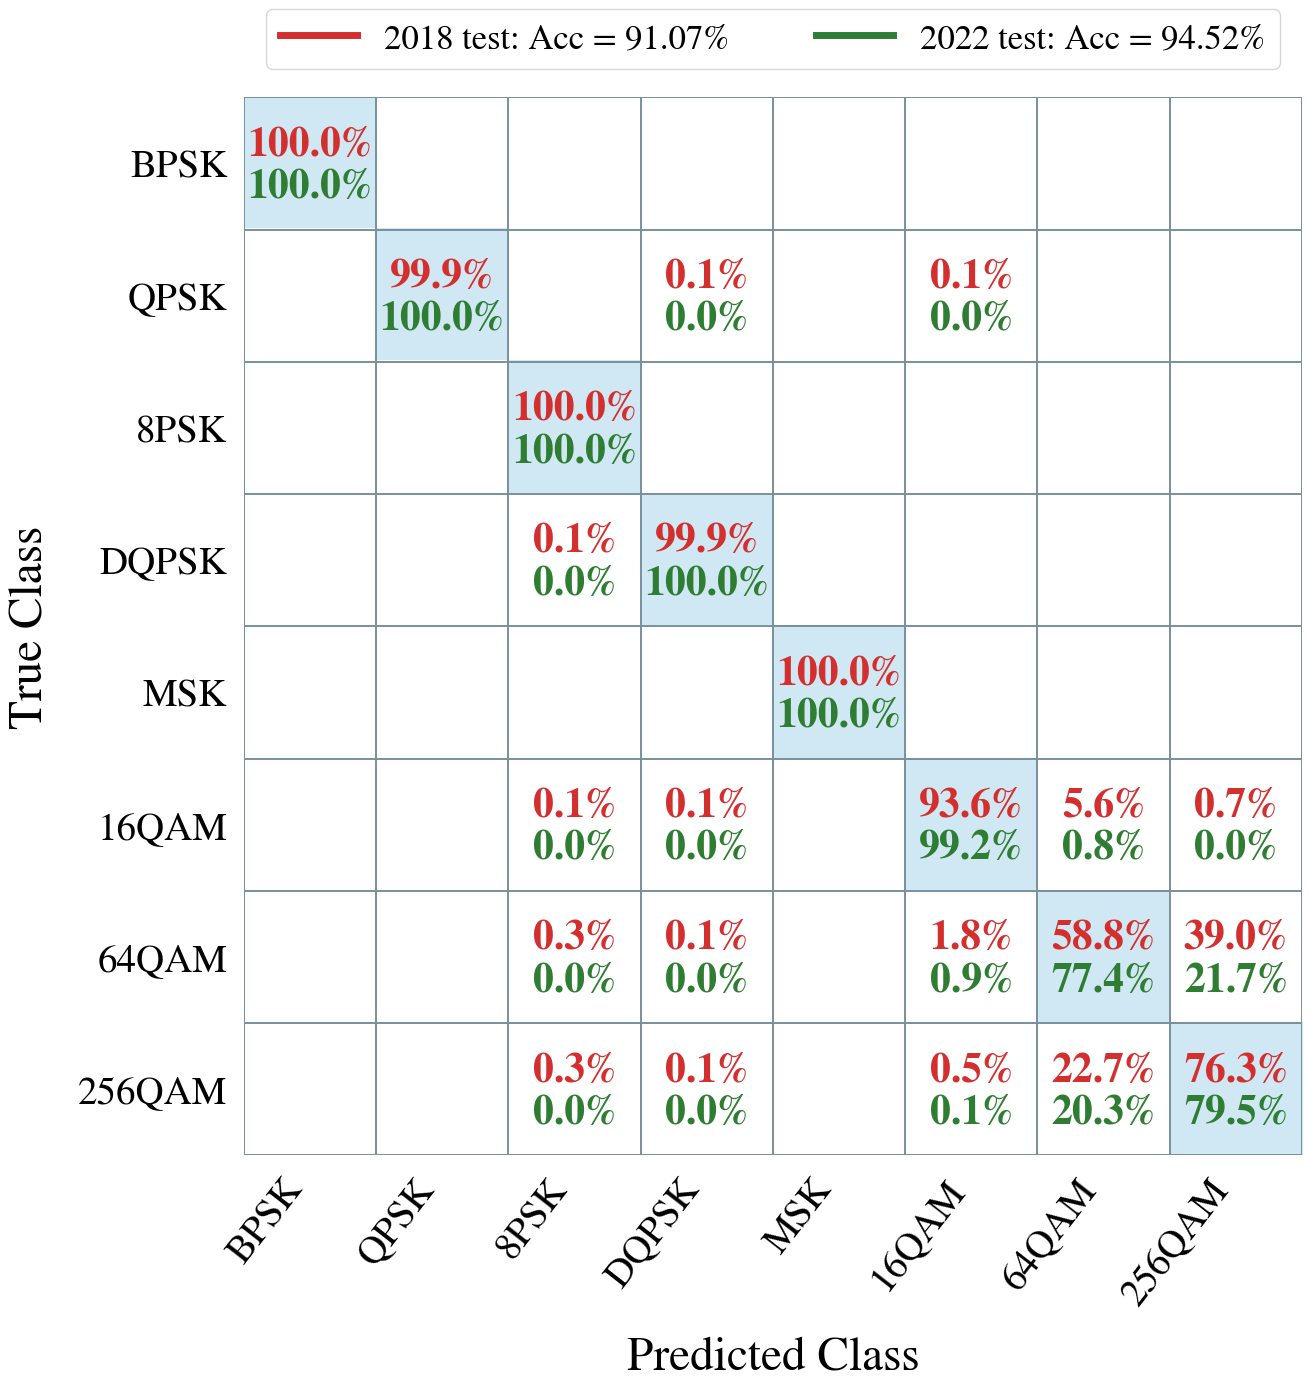

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})


def row_normalize_cm(cm):
    cm = np.asarray(cm, dtype=np.float64)
    row_sum = cm.sum(axis=1, keepdims=True)
    row_sum[row_sum == 0] = 1.0
    return cm / row_sum * 100.0


def plot_combined_confusion(cm_2018, cm_2022, acc_2018, acc_2022, class_names, save_path=None):
    cm_2018_pct = row_normalize_cm(cm_2018)
    cm_2022_pct = row_normalize_cm(cm_2022)
    n_classes = len(class_names)

    # Light blue diagonal cells, white off-diagonal cells.
    background = np.eye(n_classes)
    cmap = ListedColormap(["#FFFFFF", "#CFE8F3"])

    fig, ax = plt.subplots(figsize=(16, 14))
    ax.imshow(background, cmap=cmap, vmin=0, vmax=1, interpolation="nearest", aspect="equal")

    ax.set_xticks(np.arange(-0.5, n_classes, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_classes, 1), minor=True)
    ax.grid(which="minor", color="#78909C", linestyle="-", linewidth=1.4)
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_xticks(np.arange(n_classes))
    ax.set_yticks(np.arange(n_classes))
    ax.set_xticklabels(class_names, rotation=52, ha="right", fontsize=28)
    ax.set_yticklabels(class_names, fontsize=28)
    ax.set_xlabel("Predicted Class", fontsize=34, labelpad=18)
    ax.set_ylabel("True Class", fontsize=34, labelpad=18)

    # Two percentages per cell; blank when both display as 0.0%.
    for i in range(n_classes):
        for j in range(n_classes):
            value_2018 = cm_2018_pct[i, j]
            value_2022 = cm_2022_pct[i, j]
            if round(value_2018, 1) == 0.0 and round(value_2022, 1) == 0.0:
                continue
            ax.text(j, i - 0.14, f"{value_2018:.1f}%", ha="center", va="center",
                    color="#D32F2F", fontsize=30, fontweight="bold")
            ax.text(j, i + 0.18, f"{value_2022:.1f}%", ha="center", va="center",
                    color="#2E7D32", fontsize=30, fontweight="bold")

    legend_handles = [
        Line2D([0], [0], color="#D32F2F", linewidth=5, label=f"2018 test: Acc = {acc_2018:.2f}%"),
        Line2D([0], [0], color="#2E7D32", linewidth=5, label=f"2022 test: Acc = {acc_2022:.2f}%"),
    ]
    ax.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2,
              frameon=True, fontsize=25, handlelength=2.2, columnspacing=2.5)

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="major", length=0, pad=12)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=600, bbox_inches="tight", facecolor="white")
    plt.show()


PLOT_CLASS_ORDER = ["BPSK", "QPSK", "8PSK", "DQPSK", "MSK", "16QAM", "64QAM", "256QAM"]
cm_by_year = {}
for year in (2018, 2022):
    rows = evaluated.loc[evaluated["dataset"].eq(year)]
    cm_by_year[year] = confusion_matrix(
        rows["true_label"], rows["final_prediction"], labels=PLOT_CLASS_ORDER,
    )

plot_combined_confusion(
    cm_2018=cm_by_year[2018],
    cm_2022=cm_by_year[2022],
    acc_2018=float(accuracy_summary.loc[2018, "accuracy_percent"]),
    acc_2022=float(accuracy_summary.loc[2022, "accuracy_percent"]),
    class_names=PLOT_CLASS_ORDER,
    save_path=None,
)
